# LAB1 - Bài 15 (Bài 6 - Trang 45): Groceries - so sánh thời gian Apriori và FP-Growth

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")
import time
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

Đinh Công Vinh Quang - 6451071061


In [2]:
import csv
with open("groceries.csv", encoding="utf-8-sig") as f:
    transactions = [[i.strip() for i in row if i.strip()] for row in csv.reader(f)]
print("Số giao dịch:", len(transactions), "| số mặt hàng:", len({i for t in transactions for i in t}))
transactions[:3]

Số giao dịch: 9835 | số mặt hàng: 169


[['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups'],
 ['tropical fruit', 'yogurt', 'coffee'],
 ['whole milk']]

In [3]:
from mlxtend.preprocessing import TransactionEncoder
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
onehot.shape

(9835, 169)

In [4]:
# min_sup từ 0.01% đến 0.1%. Giới hạn max_len = 3 để tránh bùng nổ tổ hợp khi min_sup rất nhỏ
min_sups = [0.0001, 0.0002, 0.0003, 0.0005, 0.0007, 0.001]
rows = []
for ms in min_sups:
    t = time.perf_counter(); ap = apriori(onehot, min_support=ms, use_colnames=True, max_len=3, low_memory=True); t_ap = time.perf_counter() - t
    t = time.perf_counter(); fp = fpgrowth(onehot, min_support=ms, use_colnames=True, max_len=3); t_fp = time.perf_counter() - t
    rows.append({"min_sup_%": ms * 100, "so_tap_pho_bien_apriori": len(ap), "so_tap_pho_bien_fpgrowth": len(fp),
                 "apriori_s": round(t_ap, 3), "fpgrowth_s": round(t_fp, 3)})
result = pd.DataFrame(rows)
result

,min_sup_%,so_tap_pho_bien_apriori,so_tap_pho_bien_fpgrowth,apriori_s,fpgrowth_s
0,0.01,149229,149229,1.307,2.836
1,0.02,70858,70858,0.766,1.739
2,0.03,44260,44260,0.678,1.223
3,0.05,24172,24172,0.432,0.715
4,0.07,15844,15844,0.350,0.714
5,0.10,9969,9969,0.181,0.485


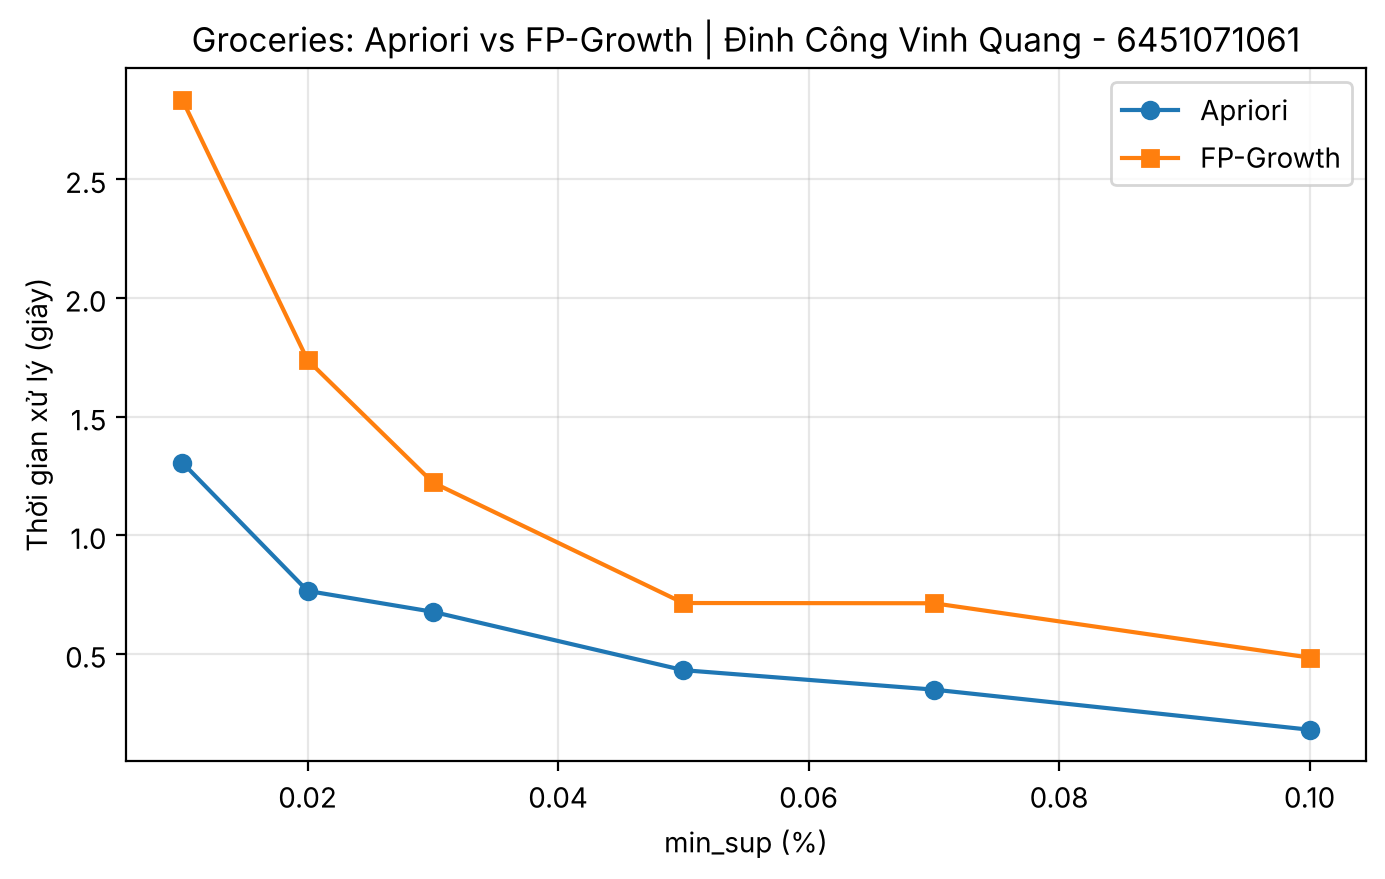

In [5]:
# c) biểu đồ so sánh thời gian xử lý
plt.figure(figsize=(8, 4.5))
plt.plot(result["min_sup_%"], result["apriori_s"], "o-", label="Apriori")
plt.plot(result["min_sup_%"], result["fpgrowth_s"], "s-", label="FP-Growth")
plt.xlabel("min_sup (%)"); plt.ylabel("Thời gian xử lý (giây)")
plt.title(f"Groceries: Apriori vs FP-Growth | {HO_TEN} - {MSSV}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Nhận xét và giải thích:**
- Hai thuật toán cho cùng số tập phổ biến ở mọi mức min_sup (đã in ở cột `so_tap_pho_bien_*`), nên chỉ khác nhau về thời gian.
- Khi min_sup giảm, số tập phổ biến tăng rất nhanh nên thời gian của cả hai đều tăng.
- Kết quả đo thực tế (xem bảng/biểu đồ): với `max_len = 3` và `low_memory=True`, bản Apriori của mlxtend lại chạy nhanh hơn FP-Growth. Điều này khác với lý thuyết chung "FP-Growth nhanh hơn" vì: (1) dữ liệu Groceries rất thưa, giao dịch ngắn (trung bình khoảng 4 mặt hàng) nên bước sinh ứng viên của Apriori rẻ; (2) giới hạn `max_len = 3` chặn việc Apriori sinh tập lớn; (3) cài đặt Apriori của mlxtend dùng phép toán ma trận vector hóa, còn FP-Growth tốn chi phí dựng cây FP và duyệt cây bằng Python.
- Lý thuyết: FP-Growth chỉ quét CSDL 2 lần và không sinh ứng viên nên có lợi thế khi dữ liệu dày/giao dịch dài hoặc khi không giới hạn độ dài tập phổ biến.